# Notebook 01 — Implementación y simulación

Este notebook cubre dos problemas del taller:

- **Problema 4.** Comprobar que los modelos programados desde cero funcionan bien, con pruebas automáticas y comparándolos con scikit-learn.
- **Problema 5.** Usar esos mismos modelos en una simulación para ver cómo la regularización cambia el sesgo, la varianza y la selección de variables.

Los modelos están en `modelos.py`. Aquí solo se importan, se prueban y se usan.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
# De scikit-learn solo usamos el escalador, una métrica y los modelos de referencia para comparar.
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import log_loss
from sklearn.preprocessing import StandardScaler

# Nuestros modelos y funciones, programados desde cero en modelos.py.
from modelos import (SEMILLA, LassoProximal, RegresionLinealGD, RegresionLogisticaGD,
                     RegresionOLS, RegresionRidge, gradiente_lineal, gradiente_logistico,
                     objetivo_lineal, objetivo_logistico, perdida_logistica, sigmoid)

# Carpetas donde se guardan los resultados que pide el taller.
RESULTADOS = Path("resultados")
PARAMETROS = RESULTADOS / "parametros"
PARAMETROS.mkdir(parents=True, exist_ok=True)

# Formato de tablas y gráficas.
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

print("NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

NumPy 2.2.6 | pandas 2.3.2 | scikit-learn 1.7.2


# Problema 4. Modelos desde cero y verificación numérica

## Datos de prueba

Para probar los modelos usamos datos simulados, donde sabemos cuál es la respuesta correcta. Son datos "fáciles": las columnas son independientes y tienen la misma escala, así que los algoritmos deberían converger rápido y coincidir con scikit-learn.

- **Regresión:** 300 filas y 5 columnas. La respuesta es $y = Xw^\star + 3 + \text{ruido}$, con $w^\star=(2,-1,0,0,0.5)$.
- **Clasificación:** 300 filas y 4 columnas. La etiqueta se sortea con probabilidad $\sigma(Xw^\star - 0.5)$, con $w^\star=(1.5,-1,0.5,0)$. Como la etiqueta es aleatoria, las dos clases se mezclan (no son separables), y por eso la logística tiene un mínimo finito.

Las columnas se estandarizan (media 0 y desviación 1). Aquí no hay conjunto de prueba, así que el escalador se ajusta con todas las filas.

In [2]:
# Generador de números aleatorios con la semilla del taller.
rng = np.random.default_rng(SEMILLA)

# --- Datos de regresión: y = X w_real + 3 + ruido ---
N, D = 300, 5
w_real = np.array([2.0, -1.0, 0.0, 0.0, 0.5])
X_reg_crudo = rng.normal(size=(N, D))
y_reg = X_reg_crudo @ w_real + 3.0 + rng.normal(size=N)
X_reg = StandardScaler().fit_transform(X_reg_crudo)

# --- Datos de clasificación: la etiqueta se sortea con probabilidad sigmoid(X w_clas - 0.5) ---
w_clas = np.array([1.5, -1.0, 0.5, 0.0])
X_clas_crudo = rng.normal(size=(N, 4))
probabilidad_real = sigmoid(X_clas_crudo @ w_clas - 0.5)
y_clas = (rng.random(N) < probabilidad_real).astype(int)
X_clas = StandardScaler().fit_transform(X_clas_crudo)

print("Regresión:", X_reg.shape, "| Clasificación:", X_clas.shape,
      "| proporción de positivos:", round(y_clas.mean(), 3))

Regresión: (300, 5) | Clasificación: (300, 4) | proporción de positivos: 0.447


## 4a. Implementación

Todos los modelos de `modelos.py` funcionan como los de scikit-learn: `fit` entrena, `predict` predice y `objetivo` calcula la función de costo con los parámetros aprendidos.

| Clase | Cómo se entrena | Qué minimiza |
|---|---|---|
| `RegresionOLS` | Mínimos cuadrados con `np.linalg.lstsq` | $J_{reg}$ (error cuadrático) |
| `RegresionRidge` | Resolviendo un sistema lineal con `np.linalg.solve` | $J_{reg}+\frac{\lambda_2}{2}\lVert w\rVert^2$ |
| `RegresionLinealGD` | Descenso por gradiente | $J_{reg}+\frac{\lambda_2}{2}\lVert w\rVert^2$ |
| `LassoProximal` | Gradiente proximal: paso de gradiente y luego umbral suave | $J_{reg}+\lambda_1\lVert w\rVert_1$ |
| `RegresionLogisticaGD` | Descenso por gradiente | $J_{log}+\frac{\lambda_2}{2}\lVert w\rVert^2$ |

En todos el intercepto $b$ no se penaliza.

**Cómo funcionan los métodos iterativos**

- **Tamaño del paso.** Se usa $\eta = 1/L$. $L$ mide qué tan rápido puede cambiar el gradiente (es una cota de su constante de Lipschitz). Con ese paso el objetivo nunca sube. Para la regresión lineal $L=\sigma_{\max}(\tilde X)^2/N+\lambda_2$, y para la logística se divide entre 4 porque $p(1-p)\le 1/4$.
- **Cuándo parar.** Cuando el cambio de los parámetros en una iteración (incluido $b$), dividido por $\eta$, es menor que `tol = 1e-8`. Sin L1 esto equivale a pedir que el gradiente sea casi cero. En Lasso es el "residuo proximal", que solo vale cero en el óptimo. Como máximo se hacen 100 000 iteraciones.
- **Qué se guarda.** El objetivo completo en cada iteración, el número de iteraciones, el último residuo y el motivo de parada (convergencia, máximo de iteraciones o divergencia).
- **Reinicio.** Cada `fit` empieza desde $w=0,\ b=0$, salvo que se pida `warm_start=True`.
- **Validaciones.** Si las entradas tienen NaN, dimensiones incorrectas o hiperparámetros inválidos, el modelo lanza `ValueError`.

**Código de clase.** Las clases de descenso por gradiente, la sigmoide estable y la actualización proximal parten del notebook de regresión de clase. 

In [3]:
# Intensidades de regularización usadas en las pruebas (valores moderados).
lam1, lam2, lam2_log = 0.1, 0.1, 0.01

# Cada entrada guarda: (modelo sin entrenar, X, y).
modelos_4a = {
    "OLS (lstsq)":        (RegresionOLS(), X_reg, y_reg),
    "Ridge (solve)":      (RegresionRidge(lam2), X_reg, y_reg),
    "Lineal GD + L2":     (RegresionLinealGD(lam2=lam2), X_reg, y_reg),
    "Lasso proximal":     (LassoProximal(lam1), X_reg, y_reg),
    "Logística GD + L2":  (RegresionLogisticaGD(lam2=lam2_log), X_clas, y_clas),
}

# Entrenamos cada modelo y anotamos cómo terminó el ajuste.
filas = []
for nombre, (modelo, X, y) in modelos_4a.items():
    modelo.fit(X, y)
    filas.append({
        "modelo": nombre,
        # eta_ y residuo_final_ solo existen en los modelos iterativos (NaN en OLS y Ridge).
        "eta": getattr(modelo, "eta_", np.nan),
        "iteraciones": modelo.n_iter_,
        "motivo de parada": modelo.motivo_parada_,
        "residuo final": getattr(modelo, "residuo_final_", np.nan),
        "objetivo final F": modelo.objetivo_final_,
    })
pd.DataFrame(filas).set_index("modelo")

,eta,iteraciones,motivo de parada,residuo final,objetivo final F
modelo,,,,,
OLS (lstsq),NaN,0,solucion directa,NaN,0.5020
Ridge (solve),NaN,0,solucion directa,NaN,0.7320
Lineal GD + L2,0.7520,18,convergencia,5.2815e-09,0.7320
Lasso proximal,0.8132,19,convergencia,5.3126e-09,0.8308
Logística GD + L2,3.3511,52,convergencia,8.7966e-09,0.4672


### Historial de convergencia

Pregunta: ¿cuántas iteraciones necesita cada método y cómo baja el objetivo?

Se grafica el objetivo completo $F$ en cada iteración. El historial se exporta a `resultados/p4_historial_convergencia.csv`.

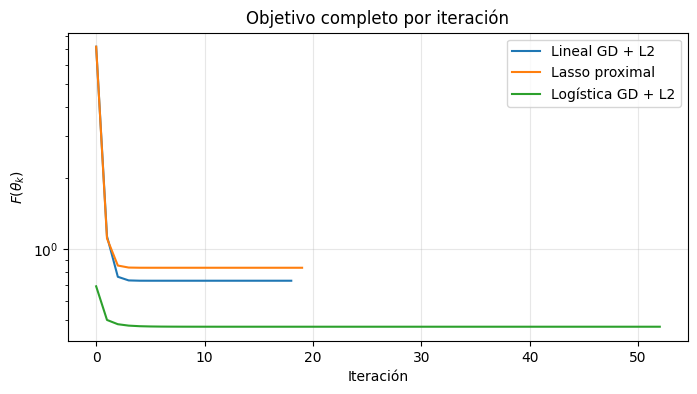

In [4]:
# Objetivo completo en cada iteración de los tres métodos iterativos.
fig, ax = plt.subplots(figsize=(8, 4))
historiales = []
for nombre in ("Lineal GD + L2", "Lasso proximal", "Logística GD + L2"):
    historial = modelos_4a[nombre][0].historial_objetivo_
    ax.plot(historial, label=nombre)
    historiales.append(pd.DataFrame({"modelo": nombre,
                                     "iteracion": np.arange(len(historial)),
                                     "objetivo": historial}))
ax.set(xlabel="Iteración", ylabel=r"$F(\theta_k)$", title="Objetivo completo por iteración", yscale="log")
ax.legend()
plt.show()

# Historial de convergencia exportado (lo pide el taller).
pd.concat(historiales).to_csv(RESULTADOS / "p4_historial_convergencia.csv", index=False)

**Interpretación.** Los tres métodos iterativos terminan por convergencia: el lineal con L2 en 18 iteraciones, Lasso en 19 y la logística en 52 (residuo menor que `tol = 1e-8`).

- El objetivo baja rápido en las primeras iteraciones y después se estabiliza. Son pocas iteraciones porque los datos son fáciles: columnas estandarizadas y casi sin correlación.
- La logística tarda más porque su curvatura real, $p(1-p)$, es menor que el $1/4$ con que se fijó el paso, así que el paso queda más corto de lo necesario.
- El descenso lineal llega al mismo objetivo que Ridge resuelto con `solve` ($F=0.7320$, tabla anterior).

## 4b. Pruebas automáticas

Cada prueba calcula un número, lo compara con un umbral fijado antes de correrla y se anota en una tabla. Al final, un `assert` hace fallar el notebook si alguna prueba no pasa. Así la verificación no depende de mirar resultados a ojo.

In [5]:
# Lista donde se acumulan los resultados de todas las pruebas.
pruebas = []


def registrar(grupo, prueba, valor, umbral, cumple):
    """Anota el resultado de una prueba en la lista `pruebas`.

    Parameters
    ----------
    grupo : str
        Tipo de prueba (gradientes, estabilidad, optimalidad, ...).
    prueba : str
        Descripción corta del caso probado.
    valor : float
        Cantidad medida.
    umbral : float
        Límite con el que se compara `valor`.
    cumple : bool
        True si la prueba pasó.
    """
    pruebas.append({"grupo": grupo, "prueba": prueba, "valor": valor,
                    "umbral": umbral, "cumple": bool(cumple)})

### Verificación de gradientes

Idea: si el gradiente que derivamos a mano es correcto, debe parecerse al que se obtiene numéricamente, moviendo un poco cada parámetro hacia arriba y hacia abajo (diferencias centrales):

$$g_k \approx \frac{F(\theta+he_k)-F(\theta-he_k)}{2h},\qquad h=10^{-6}.$$

$\theta=(b,w)$ incluye el intercepto. Se prueba en 3 puntos al azar, para la regresión lineal y la logística, con y sin L2. La diferencia se mide con

$$\delta_g=\frac{\lVert g_{\text{analítica}}-g_{\text{numérica}}\rVert_2}{\max(1,\lVert g_{\text{analítica}}\rVert_2,\lVert g_{\text{numérica}}\rVert_2)}$$

y se exige $\delta_g<10^{-5}$. La parte L1 no es derivable en cero, así que no se prueba aquí: Lasso se verifica más abajo con sus condiciones de optimalidad.

In [6]:
def gradiente_numerico(f, theta, h=1e-6):
    """Aproxima el gradiente de f en theta con diferencias centrales.

    Para cada coordenada k mueve theta_k en +h y en -h y usa
    (f(theta + h e_k) - f(theta - h e_k)) / (2h).
    """
    g = np.zeros_like(theta)
    for k in range(len(theta)):
        e = np.zeros_like(theta)
        e[k] = h
        g[k] = (f(theta + e) - f(theta - e)) / (2 * h)
    return g


def delta_g(g_ana, g_num):
    """Diferencia relativa entre el gradiente analítico y el numérico (fórmula del enunciado)."""
    escala = max(1.0, np.linalg.norm(g_ana), np.linalg.norm(g_num))
    return np.linalg.norm(g_ana - g_num) / escala


# Casos a probar: (nombre, función objetivo, función gradiente, X, y).
casos = [("lineal", objetivo_lineal, gradiente_lineal, X_reg, y_reg),
         ("logística", objetivo_logistico, gradiente_logistico, X_clas, y_clas)]
rng_grad = np.random.default_rng(SEMILLA + 1)       # generador aparte, solo para los puntos

for nombre, objetivo, gradiente, X, y in casos:
    for l2 in (0.0, 0.5):
        for punto in range(3):
            # Punto aleatorio theta = (b, w).
            theta = rng_grad.normal(size=X.shape[1] + 1)
            b, w = theta[0], theta[1:]

            # Gradiente analítico (el de modelos.py), con la derivada de b primero.
            g_w, g_b = gradiente(w, b, X, y, lam2=l2)
            g_analitico = np.r_[g_b, g_w]

            # Gradiente numérico de la misma función objetivo.
            def F(t):
                return objetivo(t[1:], t[0], X, y, lam2=l2)
            g_numerico = gradiente_numerico(F, theta)

            d = delta_g(g_analitico, g_numerico)
            registrar("gradientes", f"{nombre}, lam2={l2}, punto {punto + 1}", d, 1e-5, d < 1e-5)

pd.DataFrame(pruebas).query("grupo == 'gradientes'")

,grupo,prueba,valor,umbral,cumple
0,gradientes,"lineal, lam2=0.0, punto 1",7.4237e-10,1.0000e-05,True
1,gradientes,"lineal, lam2=0.0, punto 2",1.3032e-09,1.0000e-05,True
2,gradientes,"lineal, lam2=0.0, punto 3",8.1143e-10,1.0000e-05,True
3,gradientes,"lineal, lam2=0.5, punto 1",9.0618e-10,1.0000e-05,True
4,gradientes,"lineal, lam2=0.5, punto 2",7.1844e-10,1.0000e-05,True
5,gradientes,"lineal, lam2=0.5, punto 3",6.1734e-10,1.0000e-05,True
6,gradientes,"logística, lam2=0.0, punto 1",1.8992e-10,1.0000e-05,True
7,gradientes,"logística, lam2=0.0, punto 2",5.1293e-11,1.0000e-05,True
8,gradientes,"logística, lam2=0.0, punto 3",1.5881e-10,1.0000e-05,True
9,gradientes,"logística, lam2=0.5, punto 1",8.4402e-11,1.0000e-05,True


### Estabilidad numérica de la sigmoide y la pérdida logística

Con scores muy grandes ($z=\pm1000$) la fórmula directa $1/(1+e^{-z})$ falla, porque $e^{1000}$ no cabe en un número de punto flotante. Para evitarlo:

- **Sigmoide.** Se calcula como $\exp(-\log(1+e^{-z}))$. La función `np.logaddexp(0, -z)` obtiene $\log(1+e^{-z})$ sin calcular $e^{-z}$ directamente.
- **Pérdida.** Se calcula a partir del score con $\ell(y,z)=\log(1+e^{z})-yz$, sin pasar por $\log p$. Así nunca aparece $\log 0$ y no hace falta "recortar" la probabilidad.

La prueba se ejecuta dentro de `np.errstate(... = "raise")`: si ocurriera un desbordamiento, Python lanzaría un error. Además, cada pérdida se compara con una fórmula de referencia escrita por casos con `log1p`.

¿Por qué no recortar $p$? Si se recortara a $[10^{-15},\,1-10^{-15}]$, la pérdida de $z=1000$ con $y=0$ daría $\approx 34.5$ en lugar del valor correcto, que es $\approx 1000$.

In [7]:
def perdida_referencia(y, z):
    """Pérdida logística de una observación, escrita por casos con log1p.

    Sirve como referencia independiente: para z > 0 saca z del logaritmo para no
    calcular exp(z) con z grande.
    """
    if z > 0:
        return z + np.log1p(np.exp(-z)) - y * z
    return np.log1p(np.exp(z)) - y * z


filas = []
# errstate(..."raise") convierte cualquier desbordamiento o división por cero en un error.
with np.errstate(over="raise", invalid="raise", divide="raise"):
    for z in (-1000, -100, -1, 0, 1, 100, 1000):
        p = float(sigmoid(z))
        for y in (0, 1):
            perdida = perdida_logistica(np.array([y]), np.array([float(z)]))
            referencia = perdida_referencia(y, float(z))
            error = abs(perdida - referencia) / max(1.0, abs(referencia))

            p_valida = np.isfinite(p) and 0 <= p <= 1
            cumple = p_valida and np.isfinite(perdida) and error < 1e-12
            filas.append({"z": z, "y": y, "sigmoide": p, "pérdida": perdida, "referencia": referencia})
            registrar("estabilidad", f"z={z}, y={y}", error, 1e-12, cumple)

pd.DataFrame(filas)

,z,y,sigmoide,pérdida,referencia
0,-1000,0,0.0000e+00,0.0000e+00,0.0000e+00
1,-1000,1,0.0000e+00,1.0000e+03,1.0000e+03
2,-100,0,3.7201e-44,3.7201e-44,3.7201e-44
3,-100,1,3.7201e-44,1.0000e+02,1.0000e+02
4,-1,0,2.6894e-01,3.1326e-01,3.1326e-01
5,-1,1,2.6894e-01,1.3133e+00,1.3133e+00
6,0,0,5.0000e-01,6.9315e-01,6.9315e-01
7,0,1,5.0000e-01,6.9315e-01,6.9315e-01
8,1,0,7.3106e-01,1.3133e+00,1.3133e+00
9,1,1,7.3106e-01,3.1326e-01,3.1326e-01


### Condiciones de optimalidad: OLS, Ridge y Lasso

- **OLS con una columna repetida.** Si una columna está duplicada hay infinitas soluciones, pero cualquiera debe cumplir las ecuaciones normales $\tilde X^\top(y-\tilde X\theta)=0$. Se verifica su residuo.
- **Ridge con $\lambda_2>0$** (con la misma columna repetida). Se verifica el residuo de sus ecuaciones normales, $(\tilde X^\top\tilde X+N\lambda_2P)\theta=\tilde X^\top y$.
- **Lasso.** No se puede pedir gradiente cero, porque $|w|$ no es derivable en 0. En su lugar se revisan las condiciones de optimalidad, usando la correlación de cada columna con el residuo, $c_j=x_j^\top r/N$ con $r=y-Xw-b$:
  - si $w_j\neq0$, debe cumplirse $c_j=\lambda_1\,\mathrm{signo}(w_j)$;
  - si $w_j=0$, basta con $|c_j|\le\lambda_1$;
  - el residuo debe tener media 0 (por el intercepto).

  Se reporta la mayor violación, con columnas ortogonales ($X^\top X/N=I$) y con columnas generales.

In [8]:
# --- OLS con una columna duplicada ---
# Agregamos una copia de la primera columna: la matriz deja de tener rango completo.
X_dup = np.column_stack([X_reg, X_reg[:, 0]])
X_dup_aum = np.column_stack([np.ones(N), X_dup])          # X̃ = [1, X_dup]
ols_dup = RegresionOLS().fit(X_dup, y_reg)
theta_ols = np.r_[ols_dup.intercept_, ols_dup.coef_]

# Residuo de las ecuaciones normales: X̃ᵀ(y - X̃θ)/N debe ser ~0.
res_ols = np.linalg.norm(X_dup_aum.T @ (y_reg - X_dup_aum @ theta_ols)) / N
registrar("optimalidad", "OLS duplicada: residuo ecuaciones normales", res_ols, 1e-10, res_ols < 1e-10)

In [9]:
# --- Ridge con la misma columna duplicada ---
ridge_dup = RegresionRidge(lam2).fit(X_dup, y_reg)
theta_r = np.r_[ridge_dup.intercept_, ridge_dup.coef_]

# Residuo de las ecuaciones normales de Ridge: (X̃ᵀX̃ + N lam2 P)θ - X̃ᵀy debe ser ~0.
P = np.eye(D + 2)
P[0, 0] = 0                                               # el intercepto no se penaliza
matriz_ridge = X_dup_aum.T @ X_dup_aum + N * lam2 * P
res_ridge = np.linalg.norm(matriz_ridge @ theta_r - X_dup_aum.T @ y_reg) / N
registrar("optimalidad", "Ridge duplicada: residuo ecuaciones normales", res_ridge, 1e-10, res_ridge < 1e-10)

In [10]:
# --- Lasso: condiciones de optimalidad ---
def violacion_kkt_lasso(modelo, X, y, lam1):
    """Mayor violación de las condiciones de optimalidad de Lasso.

    Con r = y - Xw - b y c_j = x_jᵀ r / N, en el óptimo se cumple:
      c_j = lam1 * signo(w_j)   si w_j != 0,
      |c_j| <= lam1             si w_j == 0,
      media(r) = 0              (por el intercepto).
    Devuelve el mayor incumplimiento; 0 si todas se cumplen exactamente.
    """
    r = y - modelo.predict(X)
    c = X.T @ r / len(y)
    activos = modelo.coef_ != 0

    # Coeficientes distintos de cero: c_j debe valer exactamente lam1 * signo(w_j).
    if np.any(activos):
        v_activos = np.max(np.abs(c[activos] - lam1 * np.sign(modelo.coef_[activos])))
    else:
        v_activos = 0.0
    # Coeficientes en cero: solo hay violación si |c_j| supera lam1.
    if np.any(~activos):
        v_ceros = max(np.max(np.abs(c[~activos])) - lam1, 0.0)
    else:
        v_ceros = 0.0
    # Intercepto: el residuo debe tener media cero.
    v_intercepto = abs(np.mean(r))
    return max(v_activos, v_ceros, v_intercepto)


# Diseño ortogonal: columnas centradas con XᵀX/N = I (se obtiene con QR).
Z = rng.normal(size=(N, D))
Q, _ = np.linalg.qr(Z - Z.mean(axis=0))
X_ort = np.sqrt(N) * Q
y_ort = X_ort @ w_real + 3.0 + rng.normal(size=N)
lam1_ort = 0.3

lasso_ort = LassoProximal(lam1_ort).fit(X_ort, y_ort)
v = violacion_kkt_lasso(lasso_ort, X_ort, y_ort, lam1_ort)
registrar("optimalidad", "Lasso ortogonal: violación KKT", v, 1e-6, v < 1e-6)

# Diseño general (columnas no ortogonales): solo se revisan las condiciones de optimalidad.
lasso_gen = modelos_4a["Lasso proximal"][0]
v = violacion_kkt_lasso(lasso_gen, X_reg, y_reg, lam1)
registrar("optimalidad", "Lasso no ortogonal: violación KKT", v, 1e-6, v < 1e-6)

print("Lasso ortogonal  - coeficientes:", np.round(lasso_ort.coef_, 4))
print("Lasso no ortogonal - coeficientes:", np.round(lasso_gen.coef_, 4))
pd.DataFrame(pruebas).query("grupo == 'optimalidad'")

Lasso ortogonal  - coeficientes: [ 1.6228 -0.7055  0.     -0.      0.1398]
Lasso no ortogonal - coeficientes: [ 1.9322 -0.6922  0.0599 -0.      0.3074]


,grupo,prueba,valor,umbral,cumple
26,optimalidad,OLS duplicada: residuo ecuaciones normales,2.3142e-15,1.0000e-10,True
27,optimalidad,Ridge duplicada: residuo ecuaciones normales,5.6906e-16,1.0000e-10,True
28,optimalidad,Lasso ortogonal: violación KKT,2.2204e-16,1.0000e-06,True
29,optimalidad,Lasso no ortogonal: violación KKT,1.0377e-09,1.0000e-06,True


### Guardar y cargar, probabilidades y umbral

- **Guardar y cargar.** Los parámetros se guardan en JSON y se cargan en un modelo nuevo. Las predicciones deben ser idénticas, bit a bit.
- **Probabilidades.** Deben estar entre 0 y 1 y sumar uno entre las dos clases.
- **Umbral.** Cambiar $\tau$ cambia las etiquetas, pero no las probabilidades (`predict_proba`) ni la log-loss.

In [11]:
def salida_modelo(modelo, X):
    """Lo que se compara al recargar: probabilidades en la logística, predicciones en regresión."""
    if isinstance(modelo, RegresionLogisticaGD):
        return modelo.predict_proba(X)
    return modelo.predict(X)


# --- Guardar y cargar parámetros ---
for nombre in ("Ridge (solve)", "Lasso proximal", "Logística GD + L2"):
    modelo, X, _ = modelos_4a[nombre]
    ruta = PARAMETROS / f"p4_{type(modelo).__name__}.json"
    modelo.guardar_parametros(ruta)

    # Modelo nuevo, sin entrenar, que solo recibe los parámetros guardados.
    recargado = type(modelo)().cargar_parametros(ruta)
    antes = salida_modelo(modelo, X)
    despues = salida_modelo(recargado, X)
    registrar("persistencia", f"{nombre}: predicciones idénticas tras guardar/cargar",
              np.max(np.abs(antes - despues)), 0, np.array_equal(antes, despues))

# --- Probabilidades válidas ---
logistica = modelos_4a["Logística GD + L2"][0]
proba = logistica.predict_proba(X_clas)
en_rango = np.all((proba >= 0) & (proba <= 1))
error_suma = np.max(np.abs(proba.sum(axis=1) - 1))
registrar("probabilidades", "en [0, 1]", proba.min(), 0, en_rango)
registrar("probabilidades", "suman 1", error_suma, 1e-12, error_suma < 1e-12)

# --- Cambiar el umbral solo cambia las etiquetas ---
proba_base = logistica.predict_proba(X_clas)
perdida_base = log_loss(y_clas, proba_base[:, 1])
for tau in (0.1, 0.5, 0.9):
    etiquetas = logistica.predict(X_clas, tau=tau)        # esto sí cambia con tau
    proba = logistica.predict_proba(X_clas)               # esto no debe cambiar
    misma_proba = np.array_equal(proba, proba_base)
    misma_perdida = log_loss(y_clas, proba[:, 1]) == perdida_base
    sin_cambios = misma_proba and misma_perdida
    registrar("umbral", f"tau={tau}: predict_proba y log-loss sin cambios ({etiquetas.sum()} positivos)",
              int(sin_cambios), 1, sin_cambios)

pd.DataFrame(pruebas).query("grupo in ['persistencia', 'probabilidades', 'umbral']")

,grupo,prueba,valor,umbral,cumple
30,persistencia,Ridge (solve): predicciones idénticas tras gua...,0.0000,0.0000e+00,True
31,persistencia,Lasso proximal: predicciones idénticas tras gu...,0.0000,0.0000e+00,True
32,persistencia,Logística GD + L2: predicciones idénticas tras...,0.0000,0.0000e+00,True
33,probabilidades,"en [0, 1]",0.0045,0.0000e+00,True
34,probabilidades,suman 1,0.0000,1.0000e-12,True
35,umbral,tau=0.1: predict_proba y log-loss sin cambios ...,1.0000,1.0000e+00,True
36,umbral,tau=0.5: predict_proba y log-loss sin cambios ...,1.0000,1.0000e+00,True
37,umbral,tau=0.9: predict_proba y log-loss sin cambios ...,1.0000,1.0000e+00,True


### Tabla resumen de pruebas

In [12]:
# Tabla completa de pruebas (la pide el taller) y resumen por grupo.
tabla_pruebas = pd.DataFrame(pruebas)
tabla_pruebas.to_csv(RESULTADOS / "p4_pruebas.csv", index=False)

resumen = tabla_pruebas.groupby("grupo")["cumple"].agg(["count", "sum"])
display(resumen.rename(columns={"count": "pruebas", "sum": "cumplidas"}))

# Si alguna prueba falla, el notebook se detiene aquí y muestra cuál.
assert tabla_pruebas["cumple"].all(), tabla_pruebas[~tabla_pruebas["cumple"]]
print(f"Las {len(tabla_pruebas)} pruebas se cumplen.")

,pruebas,cumplidas
grupo,,
estabilidad,14,14
gradientes,12,12
optimalidad,4,4
persistencia,3,3
probabilidades,2,2
umbral,3,3


Las 38 pruebas se cumplen.


**Interpretación.** Las 38 pruebas se cumplen.

- **Gradientes.** Los $\delta_g$ están entre $10^{-11}$ y $10^{-9}$, muy por debajo de $10^{-5}$. Ese tamaño es el error de redondeo normal de las diferencias centrales con $h=10^{-6}$; no indica un error en las derivadas.
- **Estabilidad.** La sigmoide y la pérdida son finitas en los 14 casos. Con $z=\pm1000$ y la etiqueta equivocada, la pérdida es exactamente $1000$, que es el valor correcto, y no un número artificial producido por un recorte.
- **OLS con columna duplicada.** Aunque hay infinitas soluciones, la que da `lstsq` cumple las ecuaciones normales (residuo $\sim10^{-15}$).
- **Ridge.** Con $\lambda_2>0$ y la misma columna duplicada, el residuo de sus ecuaciones normales también es $\sim10^{-16}$.
- **Lasso.** Las condiciones de optimalidad se cumplen con columnas ortogonales y generales (violación $\le10^{-9}$). Los coeficientes que deben ser cero quedan exactamente en cero, porque los produce el umbral suave dentro del algoritmo.
- **Resto.** Guardar y cargar no cambia las predicciones; las probabilidades están en $[0,1]$ y suman uno; y cambiar $\tau$ solo cambia las etiquetas.

## 4c. Comparación con scikit-learn

### ¿Qué parámetro de scikit-learn corresponde a nuestro $\lambda$?

scikit-learn escribe las funciones de costo con otra escala. Por ejemplo, `Ridge` usa la suma de errores al cuadrado sin dividir por $N$, y `LogisticRegression` pone un parámetro $C$ multiplicando la pérdida en lugar de un $\lambda$ multiplicando la penalización. Multiplicar un objetivo por una constante positiva no cambia dónde está su mínimo. Por eso basta reescribir cada objetivo en nuestra convención e igualar los coeficientes de la penalización (scikit-learn 1.7.2):

| Estimador | Objetivo en scikit-learn | Reescrito en nuestra convención | Equivalencia |
|---|---|---|---|
| `LinearRegression` | $\lVert y-Xw-b\rVert^2$ | $2N\cdot J_{reg}$ | sin parámetro |
| `Ridge(alpha)` | $\lVert y-Xw-b\rVert^2+\alpha\lVert w\rVert_2^2$ | $2N\left[J_{reg}+\frac{\alpha}{2N}\lVert w\rVert_2^2\right]$ | $\alpha = N\lambda_2$ |
| `Lasso(alpha)` | $\frac{1}{2N}\lVert y-Xw-b\rVert^2+\alpha\lVert w\rVert_1$ | $J_{reg}+\alpha\lVert w\rVert_1$ | $\alpha=\lambda_1$ |
| `LogisticRegression(C)` (L2, sin pesos) | $\frac12\lVert w\rVert_2^2+C\sum_n\ell_n$ | $CN\left[J_{log}+\frac{1}{2CN}\lVert w\rVert_2^2\right]$ | $C=\dfrac{1}{N\lambda_2}$ |

En todos el intercepto no se penaliza: `LinearRegression`, `Ridge` y `Lasso` centran los datos, y `LogisticRegression` con `lbfgs` deja el intercepto fuera de la penalización.

**Ojo:** en `Ridge` y en `LogisticRegression` la equivalencia depende de $N$, así que hay que recalcularla si cambia el número de filas de entrenamiento. Por eso se compara con $N=150$ y con $N=300$.

### Cómo se compara

- **Objetivo.** Se evalúan las dos soluciones con nuestra función $F$ y se mide su diferencia relativa.
- **Predicciones.** Diferencia relativa entre las predicciones; en la logística, entre las probabilidades, no solo las etiquetas.
- **Meta.** Las dos diferencias deben ser menores que $10^{-4}$.

Las dos implementaciones reciben exactamente las mismas matrices estandarizadas.

In [13]:
def equivalencias_sklearn(N, lam1, lam2):
    """Parámetros de scikit-learn equivalentes a nuestros lambdas para N filas de entrenamiento."""
    return {"N": N,
            "Ridge alpha = N*lam2": N * lam2,
            "Lasso alpha = lam1": lam1,
            "Logistic C = 1/(N*lam2_log)": 1 / (N * lam2_log)}


tabla_equiv = pd.DataFrame([equivalencias_sklearn(n, lam1, lam2) for n in (150, 300)])
print(f"lam1 = {lam1}, lam2 = {lam2}, lam2 (logística) = {lam2_log}")
tabla_equiv

lam1 = 0.1, lam2 = 0.1, lam2 (logística) = 0.01


,N,Ridge alpha = N*lam2,Lasso alpha = lam1,Logistic C = 1/(N*lam2_log)
0,150,15.0,0.1,0.6667
1,300,30.0,0.1,0.3333


In [14]:
def dif_relativa(a, b):
    """Diferencia relativa ||a - b|| / ||b|| entre dos vectores de predicciones."""
    return np.linalg.norm(a - b) / np.linalg.norm(b)


filas = []
for n in (150, 300):
    # Las mismas matrices preparadas (primeras n filas, estandarizadas) para las dos implementaciones.
    Xr = StandardScaler().fit_transform(X_reg_crudo[:n])
    yr = y_reg[:n]
    Xc = StandardScaler().fit_transform(X_clas_crudo[:n])
    yc = y_clas[:n]
    eq = equivalencias_sklearn(n, lam1, lam2)

    # --- Regresión: (nombre, modelo propio, modelo de sklearn, lam1, lam2) ---
    pares = [
        ("OLS", RegresionOLS(), LinearRegression(), 0.0, 0.0),
        ("Ridge (solve)", RegresionRidge(lam2), Ridge(alpha=eq["Ridge alpha = N*lam2"]), 0.0, lam2),
        ("Ridge (GD)", RegresionLinealGD(lam2=lam2), Ridge(alpha=eq["Ridge alpha = N*lam2"]), 0.0, lam2),
        ("Lasso", LassoProximal(lam1), Lasso(alpha=lam1, tol=1e-12, max_iter=1_000_000), lam1, 0.0),
    ]
    for nombre, propio, ref, l1, l2 in pares:
        propio.fit(Xr, yr)
        ref.fit(Xr, yr)
        # Las dos soluciones se evalúan con NUESTRA función objetivo.
        F_p = objetivo_lineal(propio.coef_, propio.intercept_, Xr, yr, l1, l2)
        F_s = objetivo_lineal(ref.coef_, ref.intercept_, Xr, yr, l1, l2)
        filas.append({"N": n, "modelo": nombre, "F propio": F_p, "F sklearn": F_s,
                      "dif. rel. objetivo": abs(F_p - F_s) / max(1, abs(F_s)),
                      "error rel. predicción": dif_relativa(propio.predict(Xr), ref.predict(Xr)),
                      "máx |Δp|": np.nan, "etiquetas iguales": np.nan,
                      "iter. propio": propio.n_iter_, "iter. sklearn": getattr(ref, "n_iter_", None)})

    # --- Logística: se comparan probabilidades además de etiquetas ---
    propio = RegresionLogisticaGD(lam2=lam2_log).fit(Xc, yc)
    ref = LogisticRegression(C=eq["Logistic C = 1/(N*lam2_log)"], tol=1e-12, max_iter=100_000).fit(Xc, yc)
    p_p = propio.predict_proba(Xc)[:, 1]
    p_s = ref.predict_proba(Xc)[:, 1]
    F_p = objetivo_logistico(propio.coef_, propio.intercept_, Xc, yc, lam2_log)
    F_s = objetivo_logistico(ref.coef_.ravel(), ref.intercept_[0], Xc, yc, lam2_log)
    filas.append({"N": n, "modelo": "Logística L2", "F propio": F_p, "F sklearn": F_s,
                  "dif. rel. objetivo": abs(F_p - F_s) / max(1, abs(F_s)),
                  "error rel. predicción": dif_relativa(p_p, p_s),
                  "máx |Δp|": np.max(np.abs(p_p - p_s)),
                  "etiquetas iguales": np.mean(propio.predict(Xc) == ref.predict(Xc)),
                  "iter. propio": propio.n_iter_, "iter. sklearn": int(ref.n_iter_[0])})

comparacion = pd.DataFrame(filas)
objetivo_ok = comparacion["dif. rel. objetivo"] < 1e-4
prediccion_ok = comparacion["error rel. predicción"] < 1e-4
comparacion["cumple < 1e-4"] = objetivo_ok & prediccion_ok
comparacion.to_csv(RESULTADOS / "p4_comparacion_sklearn.csv", index=False)
assert comparacion["cumple < 1e-4"].all()
comparacion

,N,modelo,F propio,F sklearn,dif. rel. objetivo,error rel. predicción,máx |Δp|,etiquetas iguales,iter. propio,iter. sklearn,cumple < 1e-4
0,150,OLS,0.4294,0.4294,1.1102e-16,9.1160e-16,NaN,NaN,0,NaN,True
1,150,Ridge (solve),0.6644,0.6644,0.0000e+00,2.9957e-16,NaN,NaN,0,NaN,True
2,150,Ridge (GD),0.6644,0.6644,3.3307e-16,7.3719e-10,NaN,NaN,24,NaN,True
3,150,Lasso,0.7471,0.7471,0.0000e+00,8.4412e-10,NaN,NaN,23,11.0,True
4,150,Logística L2,0.4366,0.4366,3.3307e-16,2.0750e-08,2.1260e-08,1.0,67,10.0,True
5,300,OLS,0.5020,0.5020,0.0000e+00,6.4656e-16,NaN,NaN,0,NaN,True
6,300,Ridge (solve),0.7320,0.7320,1.1102e-16,6.1880e-16,NaN,NaN,0,NaN,True
7,300,Ridge (GD),0.7320,0.7320,1.1102e-16,4.7261e-10,NaN,NaN,18,NaN,True
8,300,Lasso,0.8308,0.8308,1.1102e-16,5.7093e-10,NaN,NaN,19,9.0,True
9,300,Logística L2,0.4672,0.4672,5.5511e-17,2.6233e-08,4.7208e-08,1.0,52,10.0,True


### Caso sin solución única: Lasso con una columna duplicada

Si dos columnas son idénticas, cualquier reparto $w_1+w_2=s$ (con el mismo signo) da las mismas predicciones y la misma penalización $|w_1|+|w_2|=|s|$ (problema 2b). Hay muchas soluciones óptimas, así que dos algoritmos correctos pueden devolver coeficientes distintos. Por eso la comparación válida es entre objetivos y predicciones, no coeficiente por coeficiente.

In [15]:
# Misma matriz de regresión con una copia de la primera columna al final.
X_dup_prep = np.column_stack([X_reg, X_reg[:, 0]])
lasso_p = LassoProximal(lam1).fit(X_dup_prep, y_reg)
lasso_s = Lasso(alpha=lam1, tol=1e-12, max_iter=1_000_000).fit(X_dup_prep, y_reg)

F_p = objetivo_lineal(lasso_p.coef_, lasso_p.intercept_, X_dup_prep, y_reg, lam1)
F_s = objetivo_lineal(lasso_s.coef_, lasso_s.intercept_, X_dup_prep, y_reg, lam1)

# Coeficientes de la columna original (posición 0) y de su copia (última posición).
caso_no_unico = pd.DataFrame({
    "w1 (columna original)": [lasso_p.coef_[0], lasso_s.coef_[0]],
    "w6 (copia de la columna 1)": [lasso_p.coef_[-1], lasso_s.coef_[-1]],
    "w1 + w6": [lasso_p.coef_[0] + lasso_p.coef_[-1], lasso_s.coef_[0] + lasso_s.coef_[-1]],
    "objetivo F": [F_p, F_s],
}, index=["propio (proximal)", "sklearn (coordenadas)"])
display(caso_no_unico)
print("Diferencia relativa de objetivo:", abs(F_p - F_s) / max(1, abs(F_s)))
print("Error relativo de predicción:  ", dif_relativa(lasso_p.predict(X_dup_prep), lasso_s.predict(X_dup_prep)))

,w1 (columna original),w6 (copia de la columna 1),w1 + w6,objetivo F
propio (proximal),0.9661,0.9661,1.9322,0.8308
sklearn (coordenadas),1.8795,0.0527,1.9322,0.8308


Diferencia relativa de objetivo: 1.1102230246251565e-16
Error relativo de predicción:   1.754395447664508e-09


**Interpretación.** Con las equivalencias derivadas, las cinco implementaciones coinciden con scikit-learn para $N=150$ y para $N=300$.

- Las diferencias relativas de objetivo son del orden de $10^{-16}$, y los errores relativos de predicción son a lo sumo $\sim3\times10^{-8}$, muy por debajo de la meta de $10^{-4}$.
- En la logística coinciden también las probabilidades (diferencia máxima $\approx5\times10^{-8}$), no solo las etiquetas.
- Al pasar de $N=150$ a $N=300$, `Ridge` necesitó cambiar $\alpha$ de 15 a 30 y `LogisticRegression` cambiar $C$ de 0.667 a 0.333. Si se hubiera dejado el mismo valor, la regularización efectiva habría cambiado.
- No hubo problemas de convergencia: todos los métodos terminaron por su criterio de tolerancia, sin agotar iteraciones.

**Columna duplicada.** Los coeficientes son muy distintos: el método proximal reparte $0.966+0.966$ y el descenso por coordenadas de scikit-learn reparte $1.880+0.053$. Sin embargo, la suma ($1.932$), el objetivo y las predicciones coinciden: las dos son soluciones óptimas del mismo problema. Comparar coeficientes uno a uno habría marcado un error que no existe. Esto también muestra que Lasso no siempre elimina una de las dos columnas: el método proximal arranca en cero, trata a las dos columnas igual y las conserva a ambas.

# Problema 5. Simulación de sesgo, varianza y selección

## 5a. Diseño de la simulación

La idea es repetir muchas veces el mismo problema, cambiando solo el ruido, para ver cómo se comportan los estimadores "en promedio".

- **Datos.** 120 filas de entrenamiento con 20 variables, y 1000 filas extra ($X_*$) que solo sirven para medir el error (filas de auditoría).
- **Variables en bloques.** Hay 4 bloques de 5 variables. Dentro de un bloque las variables tienen correlación $\rho$; entre bloques, correlación 0. Todas tienen varianza 1. Se estudian dos escenarios: $\rho=0$ (independientes) y $\rho=0.9$ (muy correlacionadas).
- **Modelo verdadero.** Solo importan 4 variables, la primera de cada bloque: $w^\star_1=3$, $w^\star_6=-2$, $w^\star_{11}=1.5$ y $w^\star_{16}=-1$. Las otras 16 tienen coeficiente 0.
- **Réplicas.** $X$ y $X_*$ se generan una sola vez y quedan fijas. Lo único que cambia es el ruido: se generan $R=40$ respuestas $y^{(r)}=Xw^\star+\varepsilon^{(r)}$, con ruido normal de varianza 1.
- **Semillas.** De la semilla maestra 2026 se sacan semillas para $X$, para $X_*$ y para cada uno de los 40 ruidos. Quedan guardadas en `resultados/p5_semillas.csv`.
- **Sin intercepto ni escalador.** El intercepto verdadero es 0 y se fija en 0 (`ajustar_intercepto=False`). No se estandariza porque todas las variables ya tienen la misma escala. Así el experimento corresponde exactamente al caso del problema 1c ($X$ fija y $b=0$).

Para generar filas con la correlación pedida se usa la descomposición de Cholesky $\Sigma_\rho=LL^\top$: si $z$ tiene variables independientes, $x=Lz$ tiene covarianza $\Sigma_\rho$.

In [16]:
# Tamaños del experimento.
N5, D5, M5, R5 = 120, 20, 1000, 40      # filas, variables, filas de auditoría, réplicas
TAM_BLOQUE = 5
RHOS = [0.0, 0.9]
LAMBDAS = [1e-3, 1e-2, 1e-1, 1.0, 10.0]

# Coeficientes verdaderos: solo la primera variable de cada bloque importa.
w_estrella = np.zeros(D5)
w_estrella[[0, 5, 10, 15]] = [3.0, -2.0, 1.5, -1.0]
SOPORTE = np.flatnonzero(w_estrella)    # posiciones 0, 5, 10, 15 = variables 1, 6, 11, 16
BLOQUE = np.arange(D5) // TAM_BLOQUE    # bloque (0 a 3) al que pertenece cada variable


def covarianza_bloques(rho):
    """Matriz de covarianza Sigma_rho de 20 x 20.

    Tiene cuatro bloques de 5 x 5 en la diagonal, con unos en la diagonal y
    rho fuera de ella. Entre bloques la covarianza es 0.
    """
    bloque = (1 - rho) * np.eye(TAM_BLOQUE) + rho * np.ones((TAM_BLOQUE, TAM_BLOQUE))
    n_bloques = D5 // TAM_BLOQUE
    return np.kron(np.eye(n_bloques), bloque)     # repite el bloque a lo largo de la diagonal


# Subsemillas: se sacan de la semilla maestra en un orden fijo y se guardan antes de usarlas.
rng_maestro = np.random.default_rng(SEMILLA)
filas_semillas = []
for rho in RHOS:
    usos = ["X", "X_aud"] + [f"ruido r={r + 1}" for r in range(R5)]
    for uso in usos:
        semilla = int(rng_maestro.integers(2**31))
        filas_semillas.append({"rho": rho, "uso": uso, "semilla": semilla})
semillas = pd.DataFrame(filas_semillas)
semillas.to_csv(RESULTADOS / "p5_semillas.csv", index=False)


def subsemilla(rho, uso):
    """Semilla registrada para un escenario (rho) y un uso ("X", "X_aud" o "ruido r=...")."""
    return semillas.query("rho == @rho and uso == @uso")["semilla"].item()


escenarios = {}
for rho in RHOS:
    # Cholesky: Sigma = L Lᵀ. Si Z tiene filas N(0, I), las filas de Z Lᵀ tienen covarianza Sigma.
    L = np.linalg.cholesky(covarianza_bloques(rho))
    Z_ent = np.random.default_rng(subsemilla(rho, "X")).normal(size=(N5, D5))
    Z_aud = np.random.default_rng(subsemilla(rho, "X_aud")).normal(size=(M5, D5))
    X = Z_ent @ L.T
    X_aud = Z_aud @ L.T

    # R respuestas con la misma X y distinto ruido (una respuesta por fila de Y).
    Y = np.empty((R5, N5))
    for r in range(R5):
        ruido = np.random.default_rng(subsemilla(rho, f"ruido r={r + 1}")).normal(size=N5)
        Y[r] = X @ w_estrella + ruido
    escenarios[rho] = (X, X_aud, Y)
    print(f"rho = {rho}: X {X.shape}, X_aud {X_aud.shape}, Y {Y.shape}")

rho = 0.0: X (120, 20), X_aud (1000, 20), Y (40, 120)


rho = 0.9: X (120, 20), X_aud (1000, 20), Y (40, 120)


## 5b. Sesgo, varianza y error

En cada escenario, y para cada una de las 40 respuestas, se ajustan: OLS, Ridge con $\lambda_2\in\Lambda$ y Lasso con $\lambda_1\in\Lambda$, donde $\Lambda=\{0.001,\ 0.01,\ 0.1,\ 1,\ 10\}$. Cada modelo usa solo su propia penalización.

Con los coeficientes de cada réplica se predice sobre las 1000 filas de auditoría, $\hat f_{rm}=x_{*m}^\top\hat w^{(r)}$, y se compara con la función verdadera $f^\star_m=x_{*m}^\top w^\star$:

- **Sesgo²** ($\hat B^2$): qué tan lejos está la predicción *promedio* (sobre las réplicas) de la verdadera.
- **Varianza** ($\hat V$): cuánto cambian las predicciones de una réplica a otra.
- **Error** ($\hat E_f$): distancia promedio entre cada predicción y la verdadera.

Las fórmulas son las del enunciado, promediadas sobre las $M$ filas de auditoría.

In [17]:
def crear_modelo_p5(nombre, lam):
    """Modelo sin intercepto (b = 0 es conocido) para la simulación."""
    if nombre == "OLS":
        return RegresionOLS(ajustar_intercepto=False)
    if nombre == "Ridge":
        return RegresionRidge(lam, ajustar_intercepto=False)
    return LassoProximal(lam, ajustar_intercepto=False)


def ajustar_replicas(nombre, lam, X, Y):
    """Ajusta un modelo nuevo para cada réplica y devuelve sus coeficientes.

    Returns
    -------
    numpy.ndarray de forma (R, D)
        Fila r = coeficientes estimados con la respuesta y^(r).
    """
    coeficientes = []
    for y in Y:
        modelo = crear_modelo_p5(nombre, lam).fit(X, y)
        # Si algún ajuste no convergiera, preferimos que el notebook falle.
        assert modelo.motivo_parada_ in ("solucion directa", "convergencia"), modelo.motivo_parada_
        coeficientes.append(modelo.coef_)
    return np.array(coeficientes)


def descomponer_error(W, X_aud):
    """Sesgo², varianza y error medio de las predicciones sobre X_aud.

    W tiene una fila de coeficientes por réplica. Devuelve (B2, V, E) con las
    fórmulas del enunciado (promedios con 1/R sobre réplicas y 1/M sobre filas).
    """
    f_estrella = X_aud @ w_estrella          # función verdadera en cada fila, forma (M,)
    F = W @ X_aud.T                          # F[r, m] = predicción de la réplica r en la fila m
    f_media = F.mean(axis=0)                 # predicción promedio sobre réplicas, forma (M,)

    B2 = np.mean((f_media - f_estrella) ** 2)          # sesgo al cuadrado
    V = np.mean(np.mean((F - f_media) ** 2, axis=0))   # varianza entre réplicas
    E = np.mean((F - f_estrella) ** 2)                 # error total
    return B2, V, E


# Coeficientes de todas las réplicas: clave (rho, modelo, lambda) -> matriz R x D.
coeficientes = {}
for rho in RHOS:
    X, X_aud, Y = escenarios[rho]
    coeficientes[(rho, "OLS", 0.0)] = ajustar_replicas("OLS", 0.0, X, Y)
    for lam in LAMBDAS:
        coeficientes[(rho, "Ridge", lam)] = ajustar_replicas("Ridge", lam, X, Y)
        coeficientes[(rho, "Lasso", lam)] = ajustar_replicas("Lasso", lam, X, Y)

# Tabla por escenario, modelo y lambda.
filas = []
for (rho, modelo, lam), W in coeficientes.items():
    X_aud = escenarios[rho][1]
    B2, V, E = descomponer_error(W, X_aud)
    filas.append({"rho": rho, "modelo": modelo, "lambda": lam, "sesgo2": B2, "varianza": V,
                  "E_f": E, "|E_f - (B2+V)|": abs(E - (B2 + V))})
tabla_p5 = pd.DataFrame(filas)

# Comprobación numérica de la descomposición E_f = B2 + V.
assert tabla_p5["|E_f - (B2+V)|"].max() < 1e-10
tabla_p5.round(4)

,rho,modelo,lambda,sesgo2,varianza,E_f,|E_f - (B2+V)|
0,0.0,OLS,0.000,0.0029,0.2220,0.2249,0.0
1,0.0,Ridge,0.001,0.0029,0.2214,0.2243,0.0
2,0.0,Lasso,0.001,0.0029,0.2178,0.2207,0.0
3,0.0,Ridge,0.010,0.0054,0.2153,0.2207,0.0
4,0.0,Lasso,0.010,0.0034,0.1840,0.1874,0.0
5,0.0,Ridge,0.100,0.1673,0.1679,0.3352,0.0
6,0.0,Lasso,0.100,0.0323,0.0539,0.0862,0.0
7,0.0,Ridge,1.000,3.7787,0.0418,3.8205,0.0
8,0.0,Lasso,1.000,2.6574,0.0298,2.6871,0.0
9,0.0,Ridge,10.000,12.7524,0.0014,12.7538,0.0


**¿Por qué se usa $1/R$?** Porque la predicción promedio $\bar f_m$ se calcula con las mismas $R$ réplicas. Con $1/R$, al desarrollar el cuadrado el término cruzado se cancela y $\hat E_f=\hat B^2+\hat V$ se cumple exactamente: es álgebra, no una aproximación. La columna $|E_f-(B^2+V)|$ lo confirma (diferencias $\sim10^{-15}$). Con $1/(R-1)$ la varianza sería insesgada, pero la suma ya no cuadraría exactamente.

**¿Por qué sumar $\sigma^2=1$ para una respuesta nueva?** $\hat E_f$ mide la distancia a la función verdadera $f^\star$. Una respuesta nueva trae además su propio ruido, $y=f^\star(x)+\varepsilon$, que ningún modelo puede predecir. Por eso el error esperado al predecir una respuesta nueva es $\hat E_f+\sigma^2=\hat E_f+1$.

### Ridge frente a las fórmulas del problema 1c

En el problema 1c se derivó que, con $X$ fija, $b=0$ y $A=X^\top X+N\lambda_2I$:

$$\mathbb E[\hat w\mid X]=A^{-1}X^\top Xw^\star,\qquad \mathrm{Cov}(\hat w\mid X)=\sigma^2A^{-1}X^\top XA^{-1}.$$

Aquí se comparan esas fórmulas con la media y la covarianza de los coeficientes de las 40 réplicas (OLS es el caso $\lambda_2=0$). Las fórmulas se evalúan con `solve`, sin invertir matrices.

In [18]:
def ridge_teorico(X, lam, sigma2=1.0):
    """Media y covarianza teóricas de Ridge con X fija y b = 0 (problema 1c).

    Con A = XᵀX + N lam I:  media = A⁻¹XᵀX w*,  cov = sigma2 · A⁻¹XᵀX A⁻¹.
    Se calculan con solve, sin invertir A.
    """
    G = X.T @ X
    A = G + len(X) * lam * np.eye(X.shape[1])
    S = np.linalg.solve(A, G)                     # S = A⁻¹ XᵀX
    media = S @ w_estrella
    cov = sigma2 * np.linalg.solve(A, S.T).T      # A⁻¹XᵀX A⁻¹ (se usa que A es simétrica)
    return media, cov


filas = []
for rho in RHOS:
    X = escenarios[rho][0]
    for modelo, lam in [("OLS", 0.0)] + [("Ridge", l) for l in LAMBDAS]:
        W = coeficientes[(rho, modelo, lam)]
        media_t, cov_t = ridge_teorico(X, lam)              # teoría
        media_e = W.mean(axis=0)                            # empírico (40 réplicas)
        cov_e = np.cov(W, rowvar=False)
        filas.append({
            "rho": rho, "modelo": modelo, "lambda": lam,
            "error rel. media": np.linalg.norm(media_e - media_t) / np.linalg.norm(media_t),
            "error rel. cov (Frobenius)": np.linalg.norm(cov_e - cov_t) / np.linalg.norm(cov_t),
        })
pd.DataFrame(filas).round(4)

,rho,modelo,lambda,error rel. media,error rel. cov (Frobenius)
0,0.0,OLS,0.000,0.0135,0.6728
1,0.0,Ridge,0.001,0.0135,0.6733
2,0.0,Ridge,0.010,0.0135,0.6779
3,0.0,Ridge,0.100,0.0131,0.7124
4,0.0,Ridge,1.000,0.0115,0.7652
5,0.0,Ridge,10.000,0.0102,0.7292
6,0.9,OLS,0.000,0.0398,0.6764
7,0.9,Ridge,0.001,0.0397,0.6804
8,0.9,Ridge,0.010,0.0385,0.7080
9,0.9,Ridge,0.100,0.0298,0.7606


**Interpretación.**

**Descomposición.** En los 22 casos (2 escenarios × 11 modelos) se cumple $\hat E_f=\hat B^2+\hat V$, salvo error de redondeo.

**Ridge frente a la teoría.**

- La media empírica difiere de la teórica en 0.5 % a 4 %.
- El error relativo de la covarianza es mayor ($\approx0.4$ a $0.8$) porque se estima una matriz de $20\times20$ con solo 40 réplicas: el error de muestreo es grande. No indica un fallo de la implementación ni de las fórmulas.

**Sesgo y varianza frente a $\lambda$.**

- En los dos modelos y los dos escenarios, al aumentar $\lambda$ el sesgo² crece y la varianza baja. El error total tiene forma de U.
- Ridge mejora poco a OLS: su mejor error es 0.221 con $\rho=0$ y 0.181 con $\rho=0.9$, frente a 0.225 y 0.200 de OLS.
- Lasso con $\lambda_1=0.1$ baja el error a 0.086 y 0.118. Funciona tan bien porque el modelo verdadero es esparso: al anular las 16 variables irrelevantes elimina mucha varianza casi sin agregar sesgo.

**Estabilidad (contraste con el problema 1c).** Con $\lambda_2=0.01$, la varianza de Ridge baja 3 % cuando $\rho=0$ ($0.222\to0.215$) y 18 % cuando $\rho=0.9$ ($0.197\to0.162$). Con variables correlacionadas, $X^\top X$ tiene valores propios pequeños, que son las direcciones donde OLS es más inestable. Ridge encoge cada dirección por el factor $d_j/(d_j+N\lambda_2)$, que es más pequeño justo cuando $d_j$ es pequeño. Es lo que predice el problema 1c: Ridge estabiliza más cuanto peor condicionado está el problema.

## 5c. Selección de variables con Lasso

**¿Cuándo un coeficiente cuenta como "seleccionado"?** Cuando $|\hat w_j|>10^{-6}$. Este valor se fijó antes de ver los resultados y no se ajusta. El gradiente proximal produce ceros exactos, así que la tolerancia solo descarta restos numéricos de la convergencia (`tol = 1e-8`).

**Métricas**, calculadas en cada réplica y promediadas sobre las 40, con $\hat S$ las variables seleccionadas y $S^\star=\{1,6,11,16\}$ las verdaderas:

- **Sensibilidad:** qué fracción de las 4 variables verdaderas se seleccionó, $|\hat S\cap S^\star|/4$.
- **Precisión:** qué fracción de las seleccionadas es verdadera, $|\hat S\cap S^\star|/|\hat S|$. No está definida si no se selecciona nada; esas réplicas se cuentan aparte.
- **Sensibilidad por bloques:** qué fracción de los 4 bloques tiene al menos una variable seleccionada. Cada bloque contiene exactamente una variable verdadera, así que la precisión por bloques siempre vale 1 y no aporta información.
- **Sustitución:** fracción de pares (réplica, bloque) en que el bloque está representado, pero no por su variable verdadera. Es decir, una variable irrelevante "ocupa el lugar" de la relevante.

In [19]:
TOL_NO_NULO = 1e-6
es_relevante = np.isin(np.arange(D5), SOPORTE)     # True en las variables 1, 6, 11 y 16


def metricas_soporte(W):
    """Recuperación del soporte por variables y por bloques, promediada sobre réplicas.

    W tiene una fila de coeficientes por réplica.
    """
    S = np.abs(W) > TOL_NO_NULO                      # S[r, j]: ¿la réplica r seleccionó la variable j?
    aciertos = (S & es_relevante).sum(axis=1)        # variables verdaderas seleccionadas, por réplica
    n_sel = S.sum(axis=1)                            # total de variables seleccionadas, por réplica

    # Precisión: solo en réplicas que seleccionaron algo.
    con_seleccion = n_sel > 0
    if np.any(con_seleccion):
        precision = np.mean(aciertos[con_seleccion] / n_sel[con_seleccion])
    else:
        precision = np.nan

    # bloque_sel[r, k]: ¿la réplica r seleccionó al menos una variable del bloque k?
    bloque_sel = np.zeros((S.shape[0], 4), dtype=bool)
    for k in range(4):
        bloque_sel[:, k] = S[:, BLOQUE == k].any(axis=1)

    # S[:, SOPORTE][r, k]: ¿la réplica r seleccionó la variable verdadera del bloque k?
    sustitucion = np.mean(bloque_sel & ~S[:, SOPORTE])

    return {
        "sensibilidad": np.mean(aciertos / len(SOPORTE)),
        "precisión": precision,
        "réplicas sin selección": int(np.sum(n_sel == 0)),
        "sensibilidad bloques": bloque_sel.mean(),
        "sustitución": sustitucion,
    }


filas, frecuencias = [], []
for rho in RHOS:
    for lam in LAMBDAS:
        W = coeficientes[(rho, "Lasso", lam)]
        filas.append({"rho": rho, "lambda": lam, **metricas_soporte(W)})

        # Frecuencia de selección: fracción de réplicas en que cada variable quedó distinta de 0.
        frec = (np.abs(W) > TOL_NO_NULO).mean(axis=0)
        fila_frec = {"rho": rho, "lambda": lam}
        for j in range(D5):
            fila_frec[f"x{j + 1}"] = frec[j]
        frecuencias.append(fila_frec)

soporte = pd.DataFrame(filas)
frecuencias = pd.DataFrame(frecuencias)
frecuencias.to_csv(RESULTADOS / "p5_frecuencias_seleccion.csv", index=False)

# Tabla completa por escenario, modelo y lambda: se agregan las métricas de soporte a las filas de Lasso.
tabla_p5 = tabla_p5.merge(soporte.assign(modelo="Lasso"), on=["rho", "modelo", "lambda"], how="left")
tabla_p5.to_csv(RESULTADOS / "p5_sesgo_varianza.csv", index=False)

soporte.round(3)

,rho,lambda,sensibilidad,precisión,réplicas sin selección,sensibilidad bloques,sustitución
0,0.0,0.001,1.000,0.202,0,1.00,0.000
1,0.0,0.010,1.000,0.218,0,1.00,0.000
2,0.0,0.100,1.000,0.516,0,1.00,0.000
3,0.0,1.000,1.000,1.000,0,1.00,0.000
4,0.0,10.000,0.000,NaN,40,0.00,0.000
5,0.9,0.001,1.000,0.205,0,1.00,0.000
6,0.9,0.010,1.000,0.254,0,1.00,0.000
7,0.9,0.100,1.000,0.491,0,1.00,0.000
8,0.9,1.000,0.725,0.826,0,0.75,0.025
9,0.9,10.000,0.000,NaN,40,0.00,0.000


In [20]:
# Frecuencia de selección de cada variable (fracción de réplicas), por escenario y lambda.
frecuencias.round(2)

,rho,lambda,x1,x2,x3,x4,x5,x6,x7,x8,...,x11,x12,x13,x14,x15,x16,x17,x18,x19,x20
0,0.0,0.00,1.0,1.00,1.00,0.98,0.98,1.0,1.00,1.00,...,1.0,0.95,0.95,1.00,1.00,1.0,0.98,1.00,1.00,1.00
1,0.0,0.01,1.0,0.85,0.90,0.95,0.85,1.0,0.95,0.88,...,1.0,0.90,0.85,0.95,0.98,1.0,0.88,0.82,0.90,0.92
2,0.0,0.10,1.0,0.20,0.25,0.20,0.20,1.0,0.42,0.20,...,1.0,0.18,0.32,0.28,0.25,1.0,0.18,0.38,0.30,0.25
3,0.0,1.00,1.0,0.00,0.00,0.00,0.00,1.0,0.00,0.00,...,1.0,0.00,0.00,0.00,0.00,1.0,0.00,0.00,0.00,0.00
4,0.0,10.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00
5,0.9,0.00,1.0,0.98,0.98,0.98,0.92,1.0,1.00,0.98,...,1.0,1.00,0.98,0.95,0.95,1.0,0.98,0.90,1.00,1.00
6,0.9,0.01,1.0,0.75,0.80,0.75,0.80,1.0,0.78,0.75,...,1.0,0.85,0.65,0.75,0.57,1.0,0.78,0.80,0.57,0.72
7,0.9,0.10,1.0,0.22,0.32,0.30,0.28,1.0,0.22,0.08,...,1.0,0.15,0.22,0.48,0.30,1.0,0.22,0.40,0.28,0.38
8,0.9,1.00,1.0,0.00,0.00,0.10,0.08,1.0,0.00,0.00,...,0.9,0.00,0.00,0.52,0.00,0.0,0.00,0.00,0.00,0.00
9,0.9,10.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,...,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00


### Trayectorias de coeficientes y error predictivo

Las trayectorias muestran cómo cambia cada coeficiente de Lasso al aumentar $\lambda_1$. Se usa la réplica 1 y una grilla fina de 30 valores entre $10^{-3}$ y $10$, solo para dibujar. Cada color es un bloque: la línea gruesa es la variable relevante del bloque y las delgadas son las irrelevantes.

A la derecha se muestra, para la grilla $\Lambda$ y las 40 réplicas, el error $\hat E_f$ de Lasso junto con su sensibilidad y su precisión. Así se ven juntas la predicción y la selección.

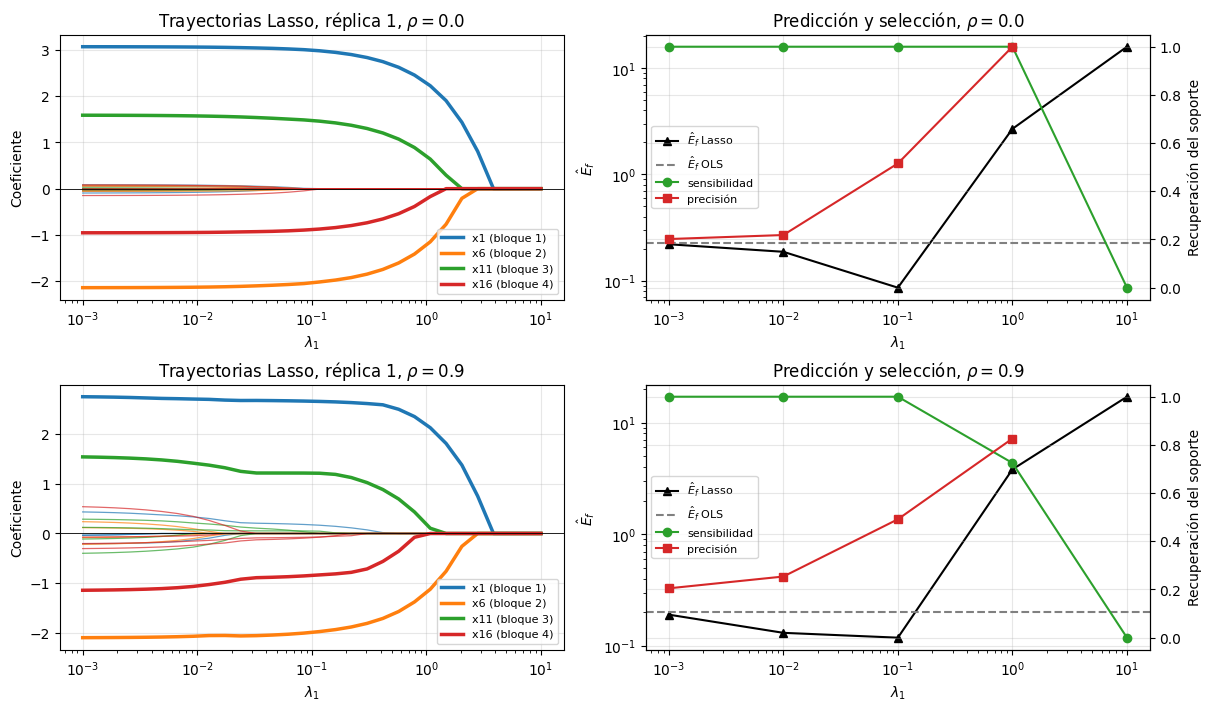

In [21]:
grilla_fina = np.logspace(-3, 1, 30)
colores = plt.rcParams["axes.prop_cycle"].by_key()["color"]

fig, ax = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for i, rho in enumerate(RHOS):
    X, _, Y = escenarios[rho]

    # --- Izquierda: trayectoria de coeficientes (réplica 1) ---
    camino = []
    for lam in grilla_fina:
        modelo = LassoProximal(lam, ajustar_intercepto=False).fit(X, Y[0])
        camino.append(modelo.coef_)
    camino = np.array(camino)                 # fila = coeficientes para un valor de lambda

    for j in range(D5):
        relevante = j in SOPORTE
        ax[i, 0].plot(grilla_fina, camino[:, j], color=colores[BLOQUE[j]],
                      lw=2.5 if relevante else 0.9, alpha=1 if relevante else 0.7,
                      label=f"x{j + 1} (bloque {BLOQUE[j] + 1})" if relevante else None)
    ax[i, 0].axhline(0, color="black", lw=0.6)
    ax[i, 0].set(xscale="log", xlabel=r"$\lambda_1$", ylabel="Coeficiente",
                 title=fr"Trayectorias Lasso, réplica 1, $\rho={rho}$")
    ax[i, 0].legend(fontsize=8)

    # --- Derecha: error (eje izquierdo) y recuperación del soporte (eje derecho) ---
    t = tabla_p5.query("rho == @rho and modelo == 'Lasso'")
    error_ols = tabla_p5.query("rho == @rho and modelo == 'OLS'")["E_f"].item()
    ax[i, 1].plot(t["lambda"], t["E_f"], "k^-", label=r"$\hat E_f$ Lasso")
    ax[i, 1].axhline(error_ols, color="gray", ls="--", label=r"$\hat E_f$ OLS")
    ax[i, 1].set(xscale="log", yscale="log", xlabel=r"$\lambda_1$", ylabel=r"$\hat E_f$",
                 title=fr"Predicción y selección, $\rho={rho}$")
    derecha = ax[i, 1].twinx()               # segundo eje vertical, compartiendo el eje x
    derecha.plot(t["lambda"], t["sensibilidad"], "o-", color=colores[2], label="sensibilidad")
    derecha.plot(t["lambda"], t["precisión"], "s-", color=colores[3], label="precisión")
    derecha.set(ylim=(-0.05, 1.05), ylabel="Recuperación del soporte")

    # Una sola leyenda con las líneas de los dos ejes.
    lineas_izq, nombres_izq = ax[i, 1].get_legend_handles_labels()
    lineas_der, nombres_der = derecha.get_legend_handles_labels()
    ax[i, 1].legend(lineas_izq + lineas_der, nombres_izq + nombres_der, fontsize=8, loc="center left")
plt.show()

**Interpretación.**

**Selección de variables.**

- Con $\lambda_1$ pequeño (0.001 y 0.01), Lasso conserva casi todas las variables: sensibilidad 1, pero precisión cercana a 0.2.
- Con $\lambda_1=1$ y $\rho=0$, recupera exactamente las 4 variables verdaderas en las 40 réplicas: sensibilidad y precisión iguales a 1.
- Con $\lambda_1=10$ anula todo; la precisión queda indefinida (40 réplicas sin selección).

**Efecto de la correlación ($\lambda_1=1$ y $\rho=0.9$).**

- La sensibilidad baja a 0.725 y la de bloques a 0.75.
- $x_{16}$ ($w^\star=-1$, la señal más débil) **nunca** se selecciona, y con ella desaparece el bloque 4 completo.
- $x_{14}$, que es irrelevante, entra en el 52 % de las réplicas. En el 2.5 % de los pares (réplica, bloque), el bloque 3 queda representado por $x_{14}$ sin su variable verdadera $x_{11}$: eso es sustitución.
- Las variables $x_4$ y $x_5$ también aparecen de vez en cuando.

Con $\rho=0$ no hay sustitución en ningún $\lambda_1$, y recuperar variables o recuperar bloques es lo mismo. Con correlación alta, recuperar el bloque es más fácil que recuperar la variable exacta.

**Predicción y selección juntas.** El menor error está en $\lambda_1=0.1$ (0.086 y 0.118), donde la precisión es apenas 0.5: la mitad de las variables elegidas son irrelevantes, aunque con coeficientes pequeños. Con $\lambda_1=1$ el soporte es perfecto (cuando $\rho=0$), pero el error, 2.69, es 30 veces mayor, porque el umbral también encoge los coeficientes verdaderos (sesgo² 2.66). En las trayectorias se ve ese encogimiento: los coeficientes relevantes se acercan a cero mucho antes de que los irrelevantes se anulen. Con $\rho=0.9$, las trayectorias de las variables irrelevantes son más grandes e irregulares para $\lambda_1$ pequeño, porque comparten la señal de la variable relevante de su bloque.

## 5d. Preguntas

**¿La regularización reduce simultáneamente sesgo y varianza?** No. En las 4 combinaciones de modelo y escenario, al aumentar $\lambda$ el sesgo² sube y la varianza baja. Por ejemplo, en Ridge con $\rho=0$ el sesgo² pasa de 0.003 a 12.75 y la varianza de 0.221 a 0.001, de $\lambda=10^{-3}$ a $10$. La regularización cambia un término por el otro: mejora el error solo cuando la varianza que quita es mayor que el sesgo que agrega. Eso ocurre en Lasso con $\lambda_1\le0.1$ y en Ridge con $\lambda_2\le0.01$; con valores mayores, el error supera al de OLS. Esto responde la pregunta central del problema 1: aumentar el sesgo puede mejorar la estimación, pero solo en un rango de $\lambda$.

**¿Mejor predicción implica recuperar el soporte correcto?** No. El menor error de Lasso ($\lambda_1=0.1$) tiene una precisión cercana a 0.5, mientras que el soporte perfecto ($\lambda_1=1$, $\rho=0$) predice 30 veces peor. Además, con $\lambda_1\le0.01$ la sensibilidad es 1 (el soporte verdadero siempre está incluido) y aun así el error es parecido al de OLS. Predecir bien y seleccionar bien son objetivos distintos, y el mismo $\lambda_1$ controla a la vez cuántas variables entran y cuánto se encogen.

**¿Cuándo una variable irrelevante funciona como sustituta de una relevante?** Cuando está correlacionada con ella. Con $\rho=0.9$, una variable del mismo bloque lleva casi la misma información y puede reproducir buena parte de su efecto en las predicciones. Con $\rho=0$ no ocurre nunca (sustitución 0 en todos los $\lambda_1$). Con $\rho=0.9$ y $\lambda_1=1$, $x_{14}$ entra en el 52 % de las réplicas y a veces sustituye a $x_{11}$. La sustitución es más probable cuando la penalización es fuerte y la señal verdadera es débil; el caso extremo es $x_{16}$, cuyo bloque desaparece por completo. Es la inestabilidad de Lasso con columnas casi iguales que se estudió en el problema 2b: qué variable del bloque se elige depende del ruido de cada réplica.